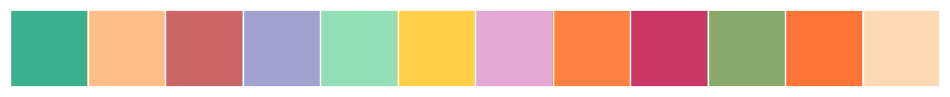

(72983, 34)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 72983 entries, 0 to 72982
Data columns (total 34 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   RefId                              72983 non-null  int64  
 1   IsBadBuy                           72983 non-null  int64  
 2   PurchDate                          72983 non-null  object 
 3   Auction                            72983 non-null  object 
 4   VehYear                            72983 non-null  int64  
 5   VehicleAge                         72983 non-null  int64  
 6   Make                               72983 non-null  object 
 7   Model                              72983 non-null  object 
 8   Trim                               70623 non-null  object 
 9   SubModel                           72975 non-null  object 
 10  Color                              72975 non-null  object 
 11  Transmission                       72974 n

In [1]:
%%time
import pandas as pd
import numpy as np
from pathlib import Path

from ml3_03_data_split_methods_jacquieb import split_by_date_ratio_train_validation_test
from ml3_03_split_visualization_jacquieb import visualize_train_valid_test_split


data_path = Path('data')
df_name = 'training.csv'
df_path = data_path / df_name
df_path.absolute()
df = pd.read_csv(df_path)
print(df.shape)
print(df.info())


In [11]:
%%time
price = df["VehBCost"]
lower_limit = price.quantile(0.01)
upper_limit = price.quantile(0.99)

below_limit = price.lt(lower_limit)
above_limit = price.gt(upper_limit)

df = df.loc[~(below_limit | above_limit)].copy()

CPU times: total: 109 ms
Wall time: 89.4 ms


In [14]:
%%time
df_train, df_valid, df_test = split_by_date_ratio_train_validation_test(
    df, validation_size=0.33, test_size=1/3, date_field='PurchDate'
)
for d in [df_train, df_valid, df_test]:
    print(d.shape)

(23930, 34)
(23309, 34)
(23573, 34)
CPU times: total: 78.1 ms
Wall time: 98 ms


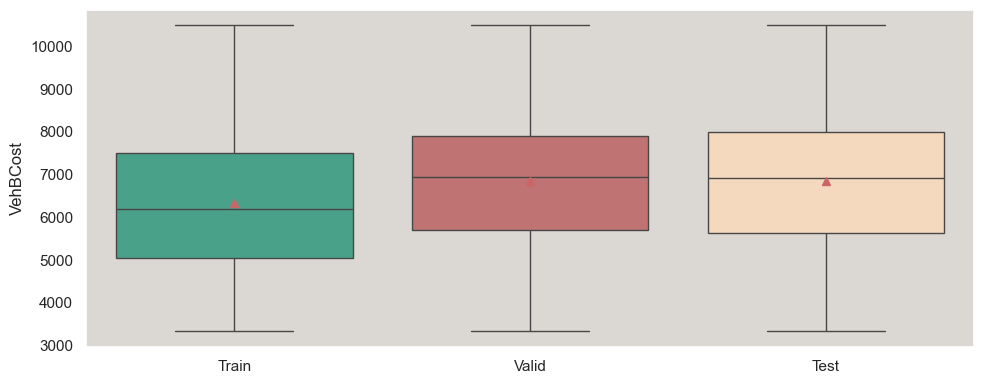

Размер df_train =  (23930, 34) 								 Размер df_valid = (23309, 34) 								 Размер df_test = (23573, 34)


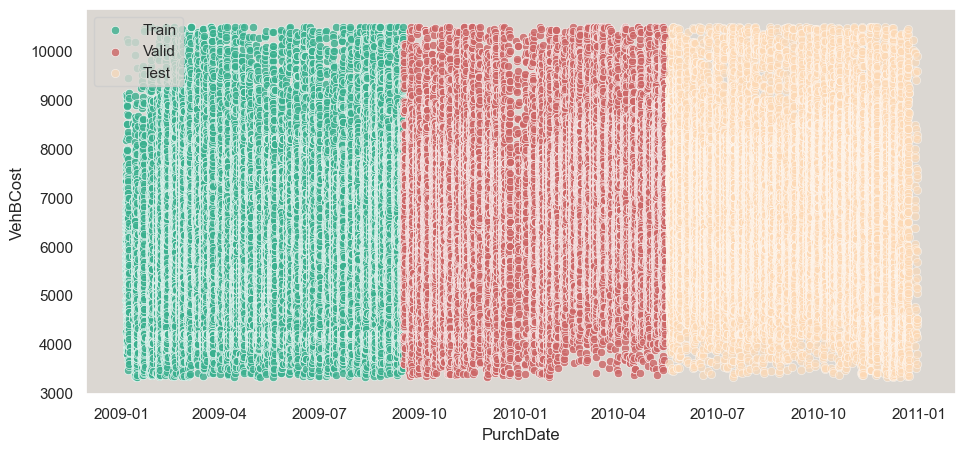

In [15]:
visualize_train_valid_test_split(df_train, df_valid, df_test, oy='VehBCost', ox='PurchDate')

In [4]:
df_train.to_csv(Path(data_path / 'df_train.csv'), index=False)
df_valid.to_csv(Path(data_path / 'df_valid.csv'), index=False)
df_test.to_csv(Path(data_path / 'df_test.csv'), index=False)